In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

In [3]:
# Load dataset
df = pd.read_csv("StudentPerformanceFactors.csv")

# Display first five records
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [4]:
# Select Exam_Score column and remove missing values
data = df['Exam_Score'].dropna()

In [6]:
# Calculate mean and standard deviation
mean = np.mean(data)
std_dev = np.std(data)

# Display mean and standard deviation
mean
std_dev

np.float64(3.8901613508847057)

In [7]:
# Generate X values for normal distribution curve
x = np.linspace(
    mean - 4 * std_dev,
    mean + 4 * std_dev,
    1000
)

In [8]:
# Calculate probability density
y = norm.pdf(x, mean, std_dev)

In [9]:
# Plot histogram and normal curve
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

(array([1.97419075e-04, 2.56644797e-03, 3.94838149e-03, 2.44799653e-02,
        2.60593179e-02, 8.60747165e-02, 6.70237758e-02, 1.44905601e-01,
        7.49205388e-02, 1.15095321e-01, 4.02734912e-02, 4.39257441e-02,
        1.04632110e-02, 6.31741039e-03, 4.93547687e-04, 6.90966761e-04,
        4.93547687e-04, 3.94838149e-04, 3.94838149e-04, 9.87095373e-05,
        5.92257224e-04, 2.96128612e-04, 2.96128612e-04, 9.87095373e-05,
        3.94838149e-04, 3.94838149e-04, 2.96128612e-04, 2.96128612e-04,
        4.93547687e-04, 1.97419075e-04]),
 array([ 55.        ,  56.53333333,  58.06666667,  59.6       ,
         61.13333333,  62.66666667,  64.2       ,  65.73333333,
         67.26666667,  68.8       ,  70.33333333,  71.86666667,
         73.4       ,  74.93333333,  76.46666667,  78.        ,
         79.53333333,  81.06666667,  82.6       ,  84.13333333,
         85.66666667,  87.2       ,  88.73333333,  90.26666667,
         91.8       ,  93.33333333,  94.86666667,  96.4       ,
      

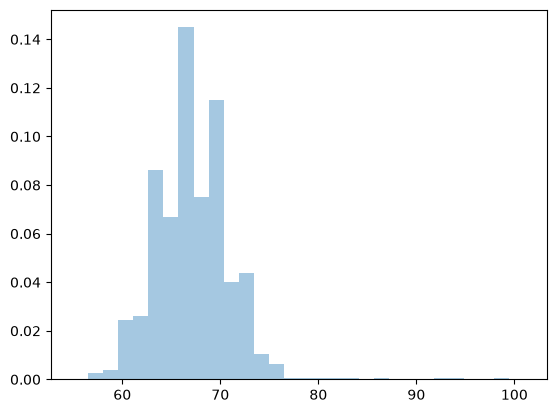

In [10]:
# Plot actual data histogram
plt.hist(
    data,
    bins=30,
    density=True,
    alpha=0.4,
    label='Actual Data'
)

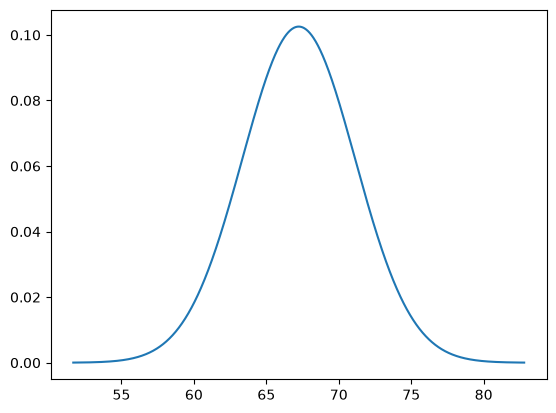

In [11]:
# Plot normal distribution curve
plt.plot(
    x,
    y,
    label='Normal Distribution Curve'
)


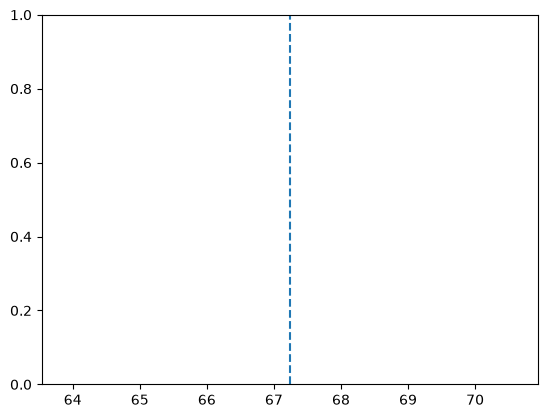

In [12]:
# Mark mean
plt.axvline(
    mean,
    linestyle='--',
    label='Mean'
)


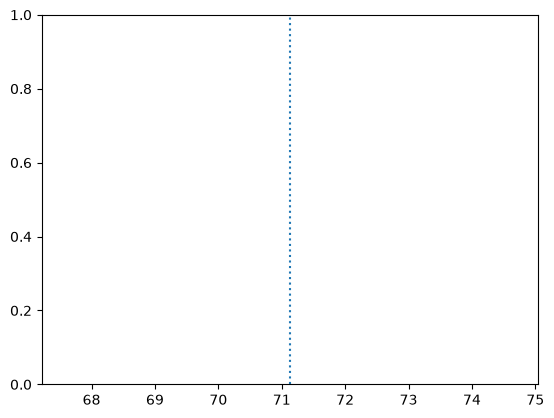

In [13]:
# Mark +1 standard deviation
plt.axvline(
    mean + std_dev,
    linestyle=':',
    label='+1 Standard Deviation'
)

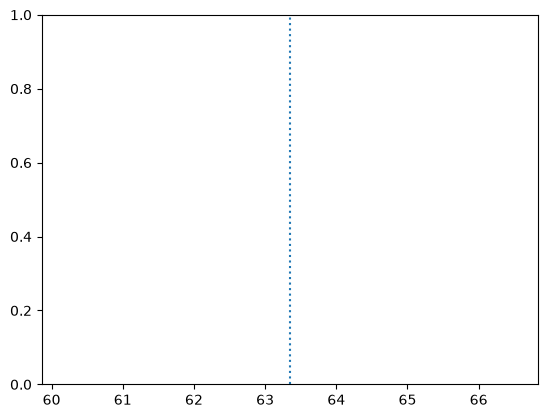

In [14]:
# Mark -1 standard deviation
plt.axvline(
    mean - std_dev,
    linestyle=':',
    label='-1 Standard Deviation'
)

C:\Users\siddh\AppData\Local\Temp\ipykernel_22040\267958826.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


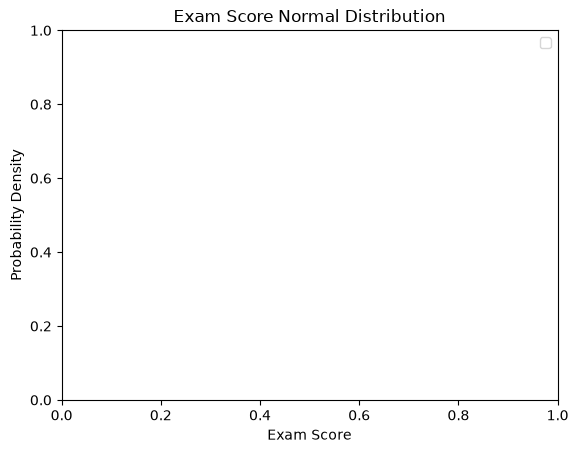

In [15]:
# Add graph details
plt.title('Exam Score Normal Distribution')
plt.xlabel('Exam Score')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

In [19]:
# Calculate percentage within 1 standard deviation
within_1std = np.mean(
    (data >= mean - std_dev) &
    (data <= mean + std_dev)
) * 100

# Calculate percentage within 2 standard deviations
within_2std = np.mean(
    (data >= mean - 2 * std_dev) &
    (data <= mean + 2 * std_dev)
) * 100

# Calculate percentage within 3 standard deviations
within_3std = np.mean(
    (data >= mean - 3 * std_dev) &
    (data <= mean + 3 * std_dev)
) * 100


In [20]:
# Create results table
results = pd.DataFrame({
    'Range': [
        'Within 1 SD',
        'Within 2 SD',
        'Within 3 SD'
    ],
    'Percentage': [
        within_1std,
        within_2std,
        within_3std
    ]
})

# Display Empirical Rule results
results

,Range,Percentage
0,Within 1 SD,75.389738
1,Within 2 SD,97.820493
2,Within 3 SD,99.212956
